# LP3 Practical 6 – Customer Segmentation using Clustering
**Aim:** Apply K-Means and Hierarchical Clustering to `sales_data_sample.csv` and use the Elbow Method to help determine the number of clusters.

**Dataset:** Download `sales_data_sample.csv` from the Kaggle dataset specified in the SPPU LP3 syllabus and place it in the same folder as this notebook.

Install dependencies if needed: `pip install pandas numpy matplotlib scikit-learn scipy`.

In [ ]:
%pip install pandas numpy matplotlib scikit-learn scipy

In [2]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

In [3]:
# 1. Load dataset
data = pd.read_csv('sales_data_sample.csv', encoding='latin1')

print('First 5 rows:')
display(data.head())
print('\nDataset shape:', data.shape)
print('\nColumns:', data.columns.tolist())

First 5 rows:


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium



Dataset shape: (2823, 25)

Columns: ['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']


In [4]:
# 2. Select numerical features used for clustering
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
X = data[features].copy()
X = X.fillna(X.median())
print('Selected features:', features)

Selected features: ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']


In [5]:
# 3. Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
# 4. Calculate WCSS for different K values (Elbow Method)
wcss = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)


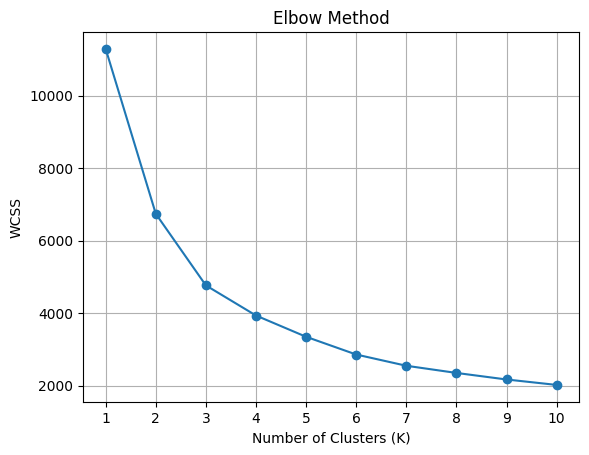

In [7]:
# 5. Plot the Elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [8]:
# 6. Apply K-Means clustering
# Here K=3 is used as an example. Adjust it if the elbow graph suggests another value.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print('K-Means results:')
display(data[['CUSTOMERNAME', 'SALES', 'KMeans_Cluster']].head())

K-Means results:


,CUSTOMERNAME,SALES,KMeans_Cluster
0,Land of Toys Inc.,2871.00,2
1,Reims Collectables,2765.90,2
2,Lyon Souveniers,3884.34,1
3,Toys4GrownUps.com,3746.70,1
4,Corporate Gift Ideas Co.,5205.27,1


In [9]:
# 7. Apply Hierarchical (Agglomerative) Clustering
hierarchical = AgglomerativeClustering(n_clusters=3)
data['Hierarchical_Cluster'] = hierarchical.fit_predict(X_scaled)

print('Hierarchical clustering results:')
display(data[['CUSTOMERNAME', 'SALES', 'Hierarchical_Cluster']].head())

Hierarchical clustering results:


,CUSTOMERNAME,SALES,Hierarchical_Cluster
0,Land of Toys Inc.,2871.00,2
1,Reims Collectables,2765.90,2
2,Lyon Souveniers,3884.34,0
3,Toys4GrownUps.com,3746.70,0
4,Corporate Gift Ideas Co.,5205.27,1


In [10]:
# 8. Display number of records in each cluster
print('K-Means cluster counts:')
print(data['KMeans_Cluster'].value_counts().sort_index())

print('\nHierarchical cluster counts:')
print(data['Hierarchical_Cluster'].value_counts().sort_index())

K-Means cluster counts:
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64

Hierarchical cluster counts:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


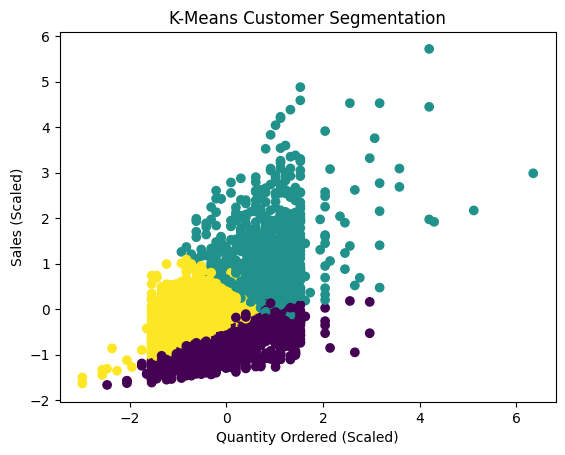

In [11]:
# 9. Visualize K-Means clusters using Quantity Ordered and Sales
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 2],
    c=data['KMeans_Cluster'], cmap='viridis'
)
plt.title('K-Means Customer Segmentation')
plt.xlabel('Quantity Ordered (Scaled)')
plt.ylabel('Sales (Scaled)')
plt.show()

In [12]:
# 10. Save the clustered dataset
data.to_csv('clustered_sales_data.csv', index=False)
print('Clustering completed successfully!')

Clustering completed successfully!


## Result
K-Means and Hierarchical Clustering are applied to the sales dataset. The Elbow graph is plotted using WCSS, cluster assignments are displayed, and the results are saved in `clustered_sales_data.csv`.

**Note:** K=3 is used as an example; choose the number of clusters based on the elbow graph.